# Project Prairie Grass (1956), 2: the physical picture

What does a plume of gas over a prairie look like, and why does it look so different at
noon and at midnight? This notebook answers in pictures: the field, single releases seen from
above and from the side, a summer of releases as an animation, and the atmosphere that shapes them.

**Getting the data.** `pgdata.py` (next to this notebook) finds the files in this order: the
folder in the environment variable `PG_DATA_DIR`; the data release this notebook sits in (the
unzipped Zenodo download, doi:[10.5281/zenodo.24462501](https://doi.org/10.5281/zenodo.24462501));
otherwise it downloads the Hugging Face copy of the same release (tag `v1.0.0`). You need
`pandas`, `matplotlib`, `scipy` and `scikit-learn` (plus `huggingface_hub` for the download).

In [1]:
import os, sys, pathlib
os.environ.setdefault("OMP_NUM_THREADS", "1")   # small data: threads only add overhead
sys.path.insert(0, str(pathlib.Path.cwd()))      # pgdata.py sits next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
print(pgdata.data_source())

import io, tempfile
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

def show_gif(anim, fps):
    """Render an animation to an embedded GIF (shows on GitHub / Hugging Face too)."""
    with tempfile.NamedTemporaryFile(suffix=".gif") as f:
        anim.save(f.name, writer=PillowWriter(fps=fps))
        plt.close(anim._fig)
        display(Image(data=open(f.name, "rb").read(), format="gif"))

arcs, towers, rt = pgdata.arcs(), pgdata.towers(), pgdata.run_table()
colors = pgdata.REGIME_COLORS

Project Prairie Grass data v1.0.0, from the data release this notebook belongs to


## 1. The field

Five half-circle arcs of samplers, 50 to 800 m from the source, all at 1.5 m height, and six
towers on the 100 m arc reaching 17.5 m. Bearings are compass bearings *from the source*. Wind
direction is where the wind comes *from*, so the plume lands at the opposite bearing. The
arcs open to the north because the summer winds there blow from the south.

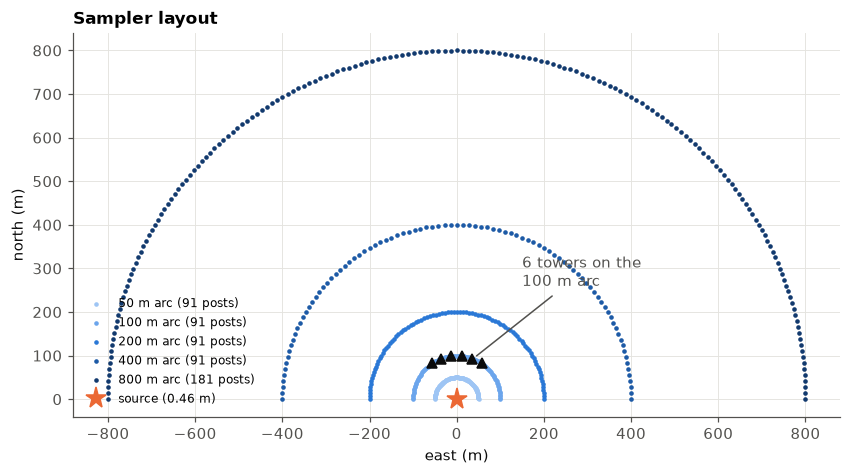

In [2]:
posts = arcs.drop_duplicates(["arc_m", "post"])[["arc_m", "post", "bearing_deg"]]
posts = posts.assign(x=posts.arc_m * np.sin(np.deg2rad(posts.bearing_deg)),
                     y=posts.arc_m * np.cos(np.deg2rad(posts.bearing_deg)))
tower_bearings = [(270 + 2 * (lo - 1) + 1) % 360 for lo in [28, 35, 42, 49, 56, 63]]   # tower t stands among posts lo..lo+6

fig, ax = plt.subplots(figsize=(9, 5))
for arc, g in posts.groupby("arc_m"):
    ax.scatter(g.x, g.y, s=4, color=pgdata.ARC_COLORS[arc], label=f"{arc} m arc ({len(g)} posts)")
for b in tower_bearings:
    ax.plot(100 * np.sin(np.deg2rad(b)), 100 * np.cos(np.deg2rad(b)), "^", color=pgdata.INK, ms=6)
ax.plot(0, 0, "*", color="#eb6834", ms=14, label="source (0.46 m)")
ax.annotate("6 towers on the\n100 m arc", (40, 95), (150, 260), color=pgdata.MUTED,
            arrowprops=dict(arrowstyle="-", color=pgdata.MUTED))
ax.set_aspect("equal"); ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)")
ax.set_title("Sampler layout"); ax.legend(loc="lower left", fontsize=8); plt.show()

## 2. One release, from above

The map on the left shows every arc sampler, coloured by concentration (log scale) and with the
wind as an arrow. On the right are the crosswind profiles: concentration against bearing on each
arc. Compare a hot afternoon (run 33) with a still night (run 59). Change the run numbers to
explore; 16 (strong convection) and 50 (a leaky vacuum line, see the remark) are interesting too.

Run 33: 1956-08-07 1255 CST (day, convective),  Q = 95 g/s,  wind 8.5 m/s from 181°,  σθ = 10.5°


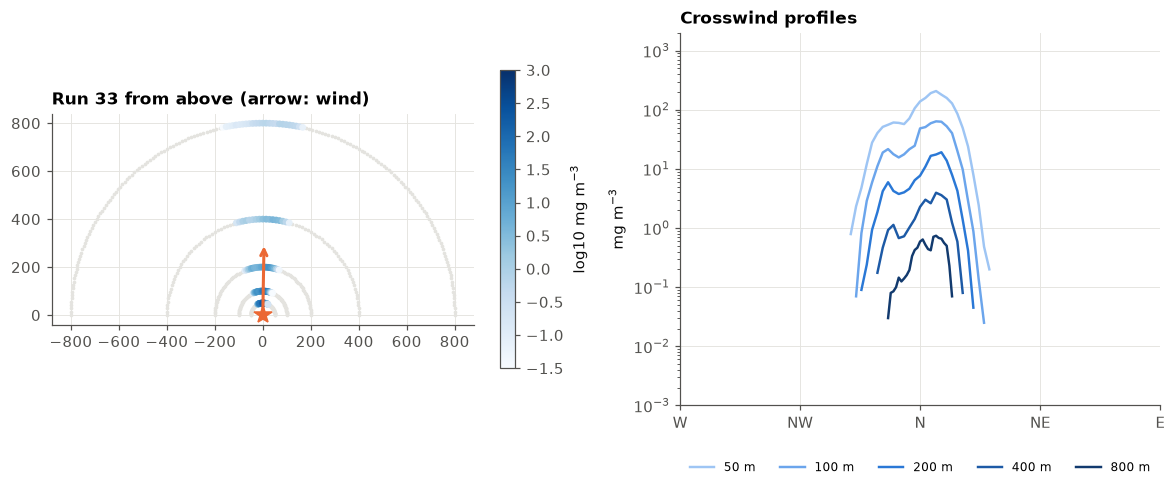

In [3]:
remarks = pgdata.run_remarks()
xy = posts.set_index(["arc_m", "post"])[["x", "y"]]

def show_run(run):
    r = rt.loc[run]
    print(f"Run {run}: {r.date} {r.time_cst} CST ({r.day_night}, {r.regime}),  Q = {r.Q_g_s:.0f} g/s,  "
          f"wind {r.u_ref:.1f} m/s from {r.dir_source_10:.0f}°,  σθ = {r.sigma_theta_source_10:.1f}°")
    for txt in remarks.loc[remarks.run == run, "remark"]:
        print("  remark:", txt)
    a = arcs[arcs.run == run].join(xy, on=["arc_m", "post"])
    m = a[a.status == "value"]
    fig, (ax, p) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
    ax.scatter(a.x, a.y, s=2, color=pgdata.GRID)
    sc = ax.scatter(m.x, m.y, c=np.log10(m.concentration_mg_m3.clip(lower=0.01)), s=12, cmap="Blues", vmin=-1.5, vmax=3)
    if pd.notna(r.dir_source_10):
        b = np.deg2rad(r.dir_source_10 + 180)
        ax.annotate("", (300 * np.sin(b), 300 * np.cos(b)), (0, 0), arrowprops=dict(arrowstyle="->", color="#eb6834", lw=2))
    ax.plot(0, 0, "*", color="#eb6834", ms=12); ax.set_aspect("equal")
    fig.colorbar(sc, ax=ax, label="log10 mg m$^{-3}$", shrink=0.8); ax.set_title(f"Run {run} from above (arrow: wind)")
    for arc in pgdata.ARCS_M:
        d = a[a.arc_m == arc].sort_values("post")
        p.plot(d.bearing_unwrapped, d.concentration_mg_m3.where(d.status == "value"), color=pgdata.ARC_COLORS[arc], label=f"{arc} m")
    p.set_yscale("log"); p.set_xlim(270, 450); p.set_ylim(1e-3, 2e3)
    p.set_xticks([270, 315, 360, 405, 450], ["W", "NW", "N", "NE", "E"]); p.set_ylabel("mg m$^{-3}$")
    p.set_title("Crosswind profiles"); p.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    plt.show()

show_run("33")

Run 59: 1956-08-25 2225 CST (night, stable),  Q = 40 g/s,  wind 2.6 m/s from 174°,  σθ = 5.2°


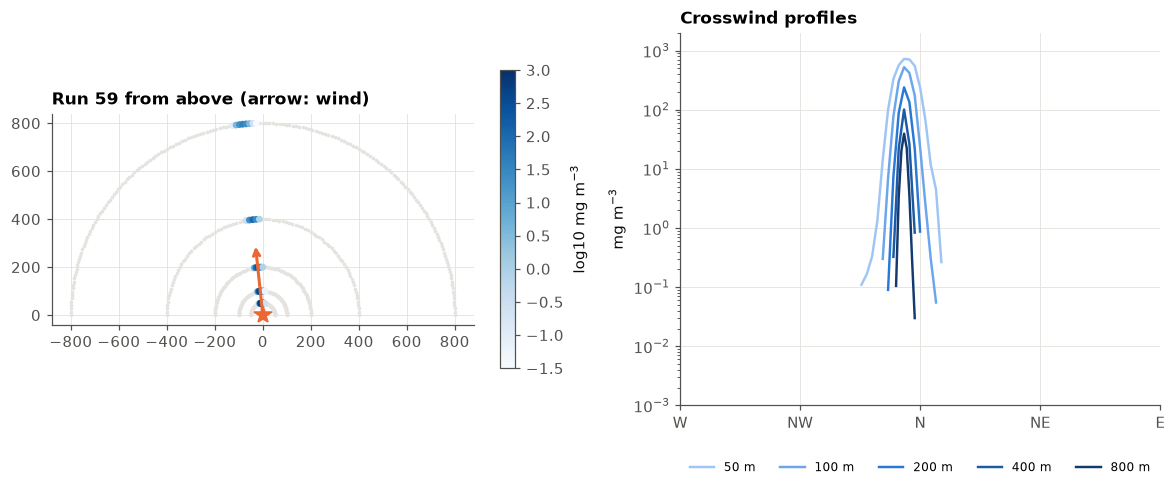

In [4]:
show_run("59")

In the afternoon (33) the plume is **wide** and fades fast with distance: hot ground drives
convection, and large eddies stir the gas sideways and upwards. At night (59) it is a **narrow
ribbon** that stays concentrated out to 800 m: the ground has cooled, the air near it is colder
and heavier than the air above (an *inversion*), and vertical mixing all but stops. The
atmosphere's **stability** decides how fast a plume dilutes, more than anything else.

## 3. A summer of plumes (animation)

All runs in time order, from early July to the end of August 1956. To compare runs released at different rates and
wind speeds, colour shows the **normalised concentration** C·u/Q (m⁻²). Notice the plume
swinging with the wind, broad by day and thin by night.

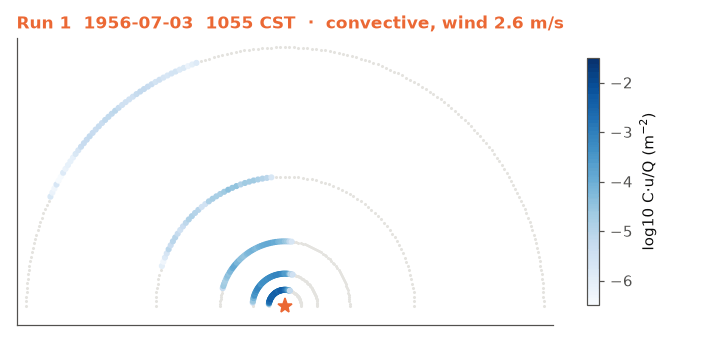

In [5]:
a = arcs[arcs.status == "value"].join(xy, on=["arc_m", "post"]).merge(rt[["Q_g_s", "u_ref"]], left_on="run", right_index=True)
a["cn"] = np.log10((a.concentration_mg_m3 / 1000 * a.u_ref / a.Q_g_s).clip(lower=1e-7))
runs = [r for r in rt.index if r in set(a.run)]

fig, ax = plt.subplots(figsize=(6.4, 3.3))
ax.scatter(posts.x, posts.y, s=1, color=pgdata.GRID)
sc = ax.scatter([], [], c=[], s=9, cmap="Blues", vmin=-6.5, vmax=-1.5)
arrow = ax.annotate("", (0, 0), (0, 0), arrowprops=dict(arrowstyle="->", color="#eb6834", lw=2))
ax.plot(0, 0, "*", color="#eb6834", ms=10); ax.set_aspect("equal"); ax.set_xlim(-830, 830); ax.set_ylim(-60, 830)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(sc, ax=ax, shrink=0.75, label="log10 C·u/Q (m$^{-2}$)")
title = ax.set_title("")

def frame(i):
    run = runs[i]; r = rt.loc[run]; d = a[a.run == run]
    sc.set_offsets(d[["x", "y"]].to_numpy()); sc.set_array(d.cn.to_numpy())
    b = np.deg2rad((r.dir_source_10 if pd.notna(r.dir_source_10) else np.nan) + 180)
    arrow.xy = (250 * np.sin(b), 250 * np.cos(b)) if np.isfinite(b) else (0, 0)
    title.set_text(f"Run {run}  {r.date}  {r.time_cst} CST  ·  {r.regime}, wind {r.u_ref:.1f} m/s")
    title.set_color(colors.get(r.regime, pgdata.INK))

fig.tight_layout()
show_gif(FuncAnimation(fig, frame, frames=len(runs)), fps=2)

## 4. The plume from the side

The six towers on the 100 m arc sampled up to 17.5 m. Day and night differ just as much
vertically. The convective plume is mixed well above the top sampler; the stable plume hugs
the ground, ten times more concentrated near it and fading by more than two orders of
magnitude within 7.5 m. (At night the narrow plume hit only one tower.)

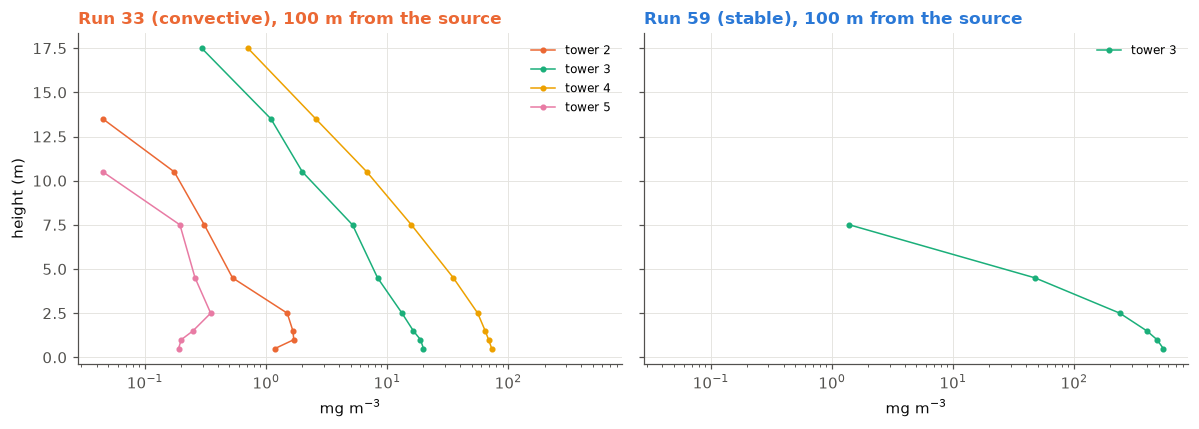

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, run in zip(axes, ["33", "59"]):
    d = towers[(towers.run == run) & (towers.status == "value")]
    for t, g in d.groupby("tower"):
        g = g.sort_values("height_m")
        ax.plot(g.concentration_mg_m3, g.height_m, marker="o", ms=3, lw=1, color=f"C{int(t) - 1}", label=f"tower {t}")
    ax.legend(fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel("mg m$^{-3}$")
    ax.set_title(f"Run {run} ({rt.regime[run]}), 100 m from the source", color=colors[rt.regime[run]])
axes[0].set_ylabel("height (m)"); plt.tight_layout(); plt.show()

## 5. Dilution with distance

The peak concentration on each arc, normalised by release rate and wind (C·u/Q), for every run.
All runs dilute with distance, but stable plumes stay 10–100 times more concentrated far
downwind. That is why night-time releases are the worst case for exposure.

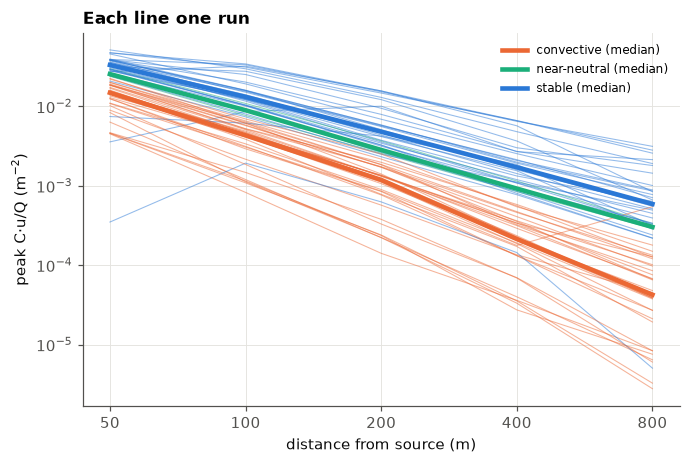

In [7]:
s = pgdata.arc_summary().merge(rt[["regime", "u_ref", "Q_g_s"]], left_on="run", right_index=True)
s = s[s.peak > 0]
s["cn"] = s.peak / 1000 * s.u_ref / s.Q_g_s
fig, ax = plt.subplots(figsize=(7, 4.4))
for run, g in s.groupby("run"):
    reg = rt.regime.get(run)
    if pd.notna(reg):
        ax.plot(g.arc_m, g.cn, color=colors[reg], lw=0.7, alpha=0.5)
for reg, g in s.groupby("regime", observed=True):
    med = g.groupby("arc_m").cn.median()
    ax.plot(med.index, med.values, color=colors[reg], lw=3, label=f"{reg} (median)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(pgdata.ARCS_M, pgdata.ARCS_M); ax.minorticks_off()
ax.set_xlabel("distance from source (m)"); ax.set_ylabel("peak C·u/Q (m$^{-2}$)")
ax.set_title("Each line one run"); ax.legend(fontsize=8); plt.show()

## 6. The atmosphere behind it

### Temperature profiles: the fingerprint of stability

Each line is one release: temperature minus the temperature at 1 m, against height (log
scale). Convective runs lean left (cooler aloft: warm air near the ground rises). Stable runs
lean right (warmer aloft: the inversion).

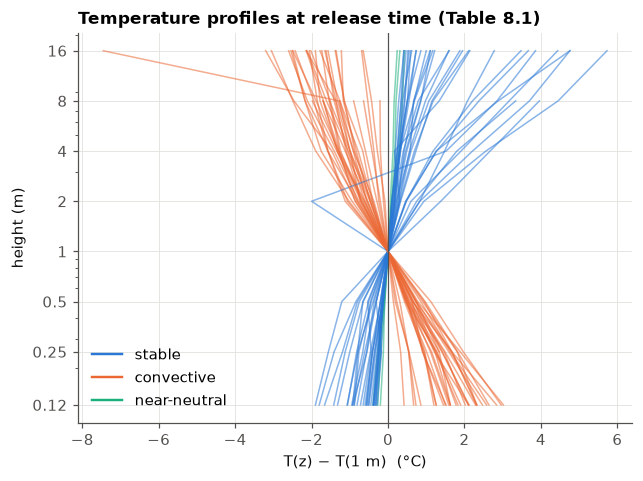

In [8]:
T = pgdata.profiles("temperature")
air = [h for h in T.columns if h > 0]
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for run, row in T[air].iterrows():
    reg = rt.regime.get(run)
    if pd.notna(reg):
        prof = (row - row[1.0]).dropna()
        ax.plot(prof.values, prof.index, color=colors[reg], alpha=0.55, lw=1)
for reg, c in colors.items():
    ax.plot([], [], color=c, label=reg)
ax.axvline(0, color=pgdata.MUTED, lw=0.8)
ax.set_yscale("log"); ax.set_yticks(air, [f"{h:g}" for h in air])
ax.set_xlabel("T(z) − T(1 m)  (°C)"); ax.set_ylabel("height (m)"); ax.legend()
ax.set_title("Temperature profiles at release time (Table 8.1)"); plt.show()

### A day in the life of the surface layer (animation)

Table 8.2 has the same profiles at hours between the releases, round the clock. The median
for each hour of the day (over 5–9 observations each) gives the daily cycle. Sunrise heats the ground and the profile
tips to lapse (convection). In the evening net radiation turns negative, the ground cools, and
the inversion builds through the night.

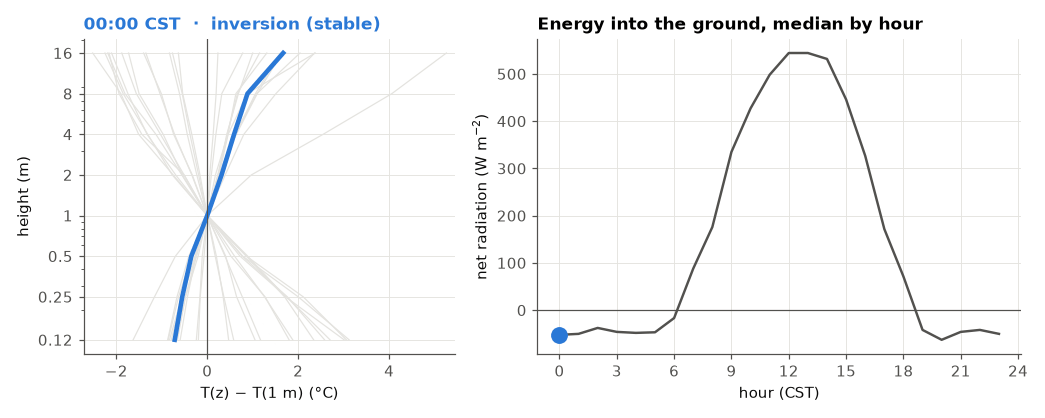

In [9]:
T2 = pgdata.profiles("temperature", table="8.2")
air2 = [h for h in T2.columns if h > 0]
hour = T2.index.get_level_values("cst").astype(int) // 100
rel = T2[air2].sub(T2[1.0], axis=0)
med = rel.groupby(hour.values).median()
mm2 = pgdata.micromet("8.2")
rn = mm2[mm2.quantity == "net_radiation"]
rn = rn[rn.value.abs() < 0.033]                            # a physical bound (solar constant)
rn_h = rn.groupby(rn.cst.astype(int) // 100).value.median() * 41868   # cal cm-2 s-1 -> W m-2

fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.5, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
for h in med.index:
    ax.plot(med.loc[h].values, air2, color=pgdata.GRID, lw=0.8)
line, = ax.plot([], [], lw=3)
ax.axvline(0, color=pgdata.MUTED, lw=0.8); ax.set_yscale("log"); ax.set_yticks(air2, [f"{z:g}" for z in air2])
ax.set_xlim(med.min().min() - 0.2, med.max().max() + 0.2)
ax.set_xlabel("T(z) − T(1 m) (°C)"); ax.set_ylabel("height (m)")
bx.plot(rn_h.index, rn_h.values, color=pgdata.MUTED); bx.axhline(0, color=pgdata.MUTED, lw=0.8)
dot, = bx.plot([], [], "o", ms=10)
bx.set_xlabel("hour (CST)"); bx.set_ylabel("net radiation (W m$^{-2}$)"); bx.set_xticks(range(0, 25, 3))
bx.set_title("Energy into the ground, median by hour")

def frame(i):
    h = med.index[i]
    stable = med.loc[h, 16.0] > med.loc[h, 0.5]
    c = colors["stable"] if stable else colors["convective"]
    line.set_data(med.loc[h].values, air2); line.set_color(c)
    ax.set_title(f"{h:02d}:00 CST  ·  {'inversion (stable)' if stable else 'lapse (convective)'}", color=c)
    if h in rn_h.index:
        dot.set_data([h], [rn_h[h]]); dot.set_color(c)

fig.tight_layout()
show_gif(FuncAnimation(fig, frame, frames=len(med)), fps=3)

### Wind profiles: the logarithmic law and its failure

Near the ground in neutral air, wind speed grows with the **logarithm** of height,
u(z) = (u*/κ) ln(z/z₀), which is a straight line on these axes. The dashed lines are fitted to
the lowest four levels. The near-neutral run follows its line. The stable run speeds up aloft,
because the inversion decouples the upper air from the drag of the ground. The convective run
falls short aloft, because mixing has evened out the speeds.

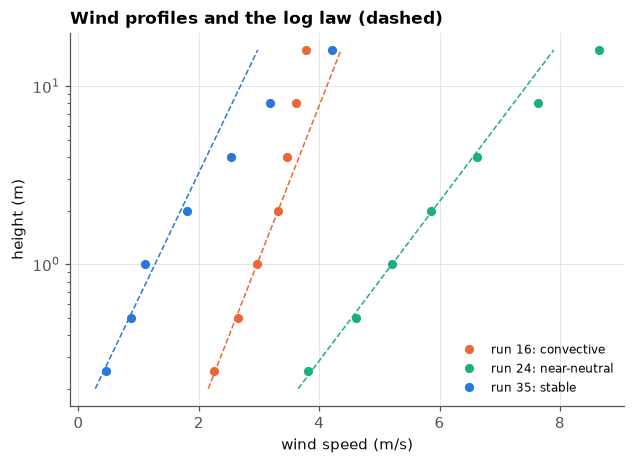

In [10]:
U = pgdata.profiles("wind_speed")
pick = {"convective": rt[rt.regime == "convective"].Ri_b.idxmin(),
        "near-neutral": rt[rt.regime == "near-neutral"].Ri_b.abs().idxmin(),
        "stable": rt[(rt.regime == "stable") & (rt.u_ref > 1.5)].Ri_b.idxmax()}
fig, ax = plt.subplots(figsize=(6.5, 4.4))
for reg, run in pick.items():
    row = U.loc[run].dropna(); row = row[row > 0]
    ax.plot(row.values, row.index, "o", color=colors[reg], label=f"run {run}: {reg}")
    z = np.array([h for h in [0.25, 0.5, 1.0, 2.0] if h in row.index])
    b, c = np.polyfit(np.log(z), row[z], 1)
    zz = np.geomspace(0.2, 16, 50); ax.plot(c + b * np.log(zz), zz, color=colors[reg], lw=1, ls="--")
ax.set_yscale("log"); ax.set_xlabel("wind speed (m/s)"); ax.set_ylabel("height (m)")
ax.set_title("Wind profiles and the log law (dashed)"); ax.legend(fontsize=8); plt.show()

**In short**

- By day, convection makes plumes wide and deep, and they dilute fast. At night an inversion
  keeps them narrow and shallow, and they carry far.
- The wind direction swings the plume around the arcs, and its gustiness (σθ) sets the plume's width.
- Temperature profiles, net radiation and the shape of the wind profile all record the same
  day/night switch.

Next: **notebook 3** turns these pictures into a model and tests it.